# PCA (Principal Component Analysis)

Find the directions along which the data varies most, and describe each point by its coordinates along just the top few. That compresses the data (fewer numbers per point), removes redundancy between correlated features, and lets you plot high-dimensional data in 2-D.

How it works:

1. **Centre** the data (subtract the mean of each feature).
2. Compute the **covariance matrix** `C = XcᵀXc / (n − 1)`.
3. Its **eigenvectors** are the principal directions (orthogonal); its **eigenvalues** are the variance along each.
4. Sort by eigenvalue, keep the top `k`. Project: `Z = Xc · Vₖ`.

The fraction of variance a component keeps is `λᵢ / Σλ`, which tells you how much information `k` components retain.

This notebook is self-contained: implementation, visuals, scikit-learn check and tests.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

Eigendecomposition of the covariance matrix with `np.linalg.eigh` (for symmetric matrices; it returns eigenvalues in *ascending* order, hence the `argsort(...)[::-1]`).

In [2]:
import numpy as np


class PCA:
    """Principal Component Analysis via eigendecomposition of the covariance matrix."""

    def __init__(self, n_components):
        self.n_components = n_components
        self.mean = None
        self.components = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean = X.mean(axis=0)
        X_centered = X - self.mean

        cov = np.cov(X_centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov)

        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        self.components = eigenvectors[:, : self.n_components].T
        total_variance = eigenvalues.sum()
        self.explained_variance_ratio_ = eigenvalues[: self.n_components] / total_variance
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return (X - self.mean) @ self.components.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)

## See it work

### 1. What the components are

Correlated 2-D data. The first principal component (long arrow) points along the direction of greatest spread; the second is perpendicular. Arrow length is two standard deviations along that direction. After `transform` the same points are rotated so the components become the new axes, and the features are uncorrelated.

explained variance ratio: [0.953 0.047] | correlation of PC1, PC2 after transform: 3.7e-16


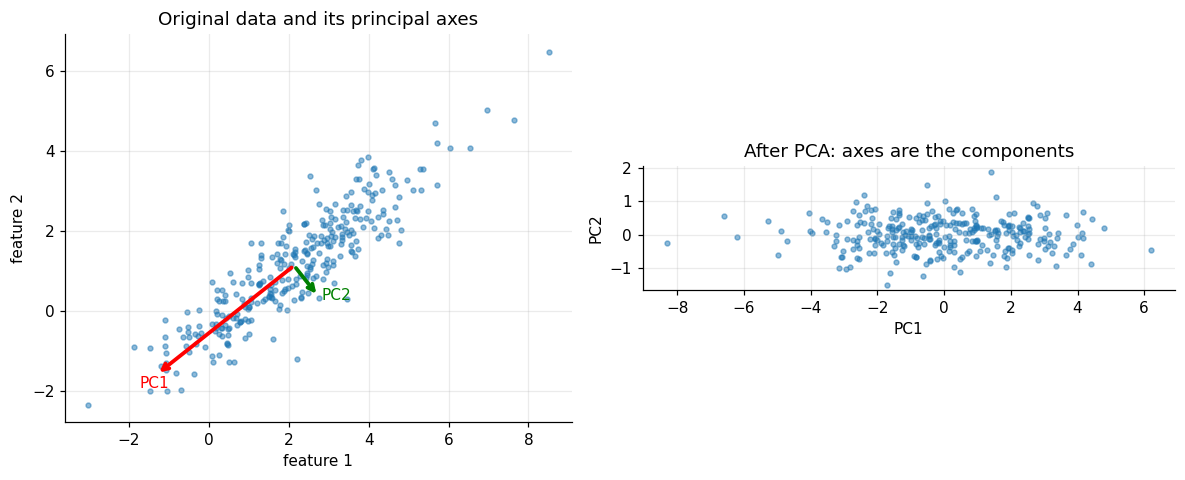

In [3]:
rng = np.random.default_rng(0)
X = rng.multivariate_normal([2, 1], [[3.0, 2.2], [2.2, 2.0]], size=300)
pca = PCA(n_components=2).fit(X)
std = np.sqrt(pca.explained_variance_ratio_ * np.trace(np.cov(X.T)))       # std along each component

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
a.scatter(*X.T, s=10, alpha=0.5)
for vec, s, c, n in zip(pca.components, std, ["r", "g"], ["PC1", "PC2"]):
    a.annotate("", xy=pca.mean + 2 * s * vec, xytext=pca.mean, arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
    a.text(*(pca.mean + 2.25 * s * vec), n, color=c)
a.set(title="Original data and its principal axes", xlabel="feature 1", ylabel="feature 2"); a.set_aspect("equal")
Z = pca.transform(X)
b.scatter(*Z.T, s=10, alpha=0.5)
b.set(title="After PCA: axes are the components", xlabel="PC1", ylabel="PC2"); b.set_aspect("equal")
print("explained variance ratio:", pca.explained_variance_ratio_.round(3), "| correlation of PC1, PC2 after transform: %.1e" % np.corrcoef(Z.T)[0, 1])
plt.tight_layout(); plt.show()

### 2. Iris: four features squeezed into a picture

Iris has 4 measurements per flower. Two components already keep about 98% of the variance, and the three species separate cleanly in that 2-D view, with no labels used.

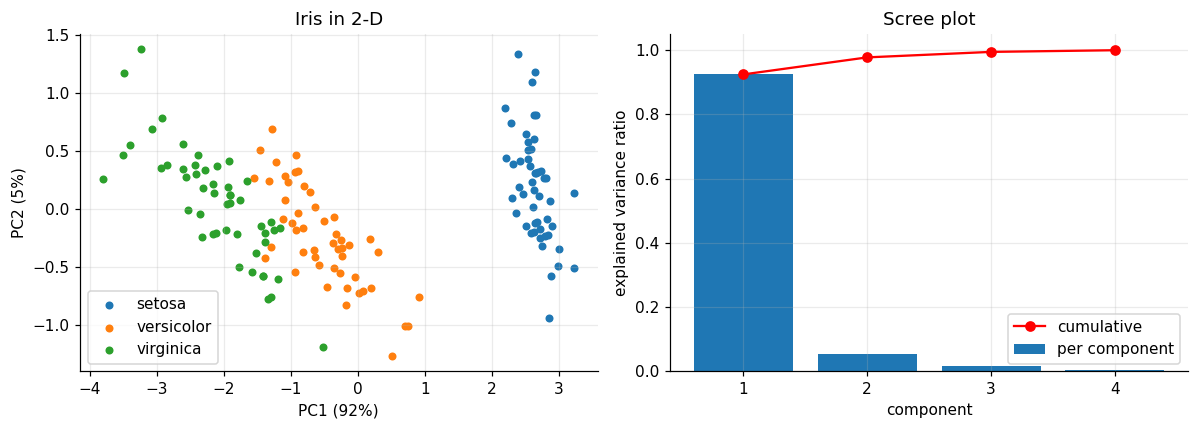

In [4]:
from sklearn.datasets import load_iris

iris = load_iris()
p4 = PCA(n_components=4).fit(iris.data)
Z = p4.transform(iris.data)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
for c, name in enumerate(iris.target_names):
    a.scatter(*Z[iris.target == c, :2].T, s=18, label=name)
a.set(xlabel=f"PC1 ({p4.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({p4.explained_variance_ratio_[1]:.0%})", title="Iris in 2-D"); a.legend()
r = p4.explained_variance_ratio_
b.bar(range(1, 5), r, label="per component"); b.plot(range(1, 5), np.cumsum(r), "ro-", label="cumulative")
b.set(xlabel="component", ylabel="explained variance ratio", title="Scree plot", xticks=range(1, 5)); b.legend()
plt.tight_layout(); plt.show()

### 3. Compression: handwritten digits

Each digit is an 8×8 image: 64 numbers. Keeping only the top `k` components and projecting back (`Z · Vₖ + mean`) gives a lossy reconstruction. With 20 to 40 of the 64 dimensions the digits are readable again, because most of the variance lives in a few directions (the printout below counts how many).

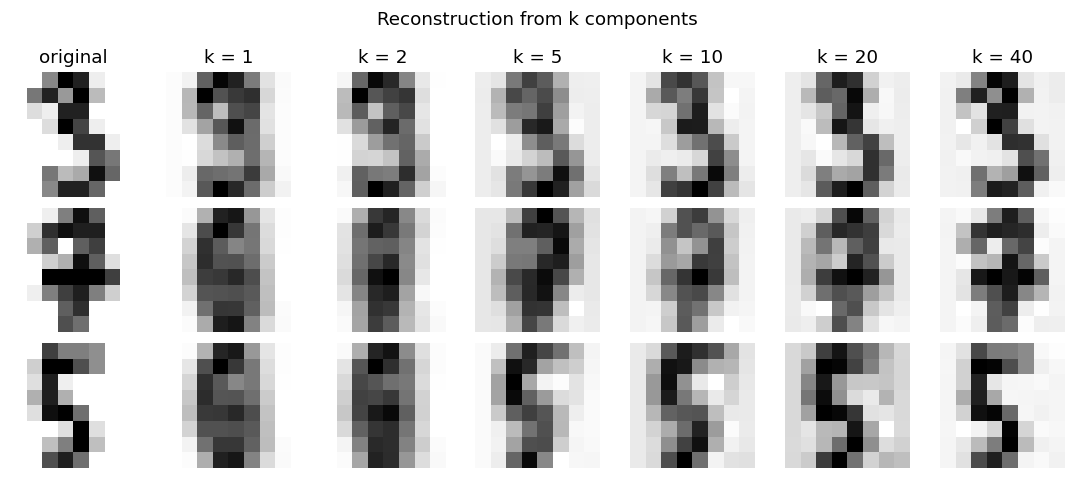

components needed for 90% of the variance: 21 of 64;  for 95%: 29


In [5]:
from sklearn.datasets import load_digits

digits = load_digits()
Xd = digits.data
pd = PCA(n_components=64).fit(Xd)
Zd = pd.transform(Xd)

def reconstruct(k):
    return Zd[:, :k] @ pd.components[:k] + pd.mean

ks = [1, 2, 5, 10, 20, 40]
rows = [3, 17, 25]
fig, axes = plt.subplots(len(rows), len(ks) + 1, figsize=(10, 4.4))
for r, i in enumerate(rows):
    axes[r, 0].imshow(Xd[i].reshape(8, 8), cmap="gray_r"); axes[r, 0].set_title("original" if r == 0 else "")
    for c, k in enumerate(ks, start=1):
        axes[r, c].imshow(reconstruct(k)[i].reshape(8, 8), cmap="gray_r")
        if r == 0: axes[r, c].set_title(f"k = {k}")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Reconstruction from k components"); plt.tight_layout(); plt.show()

cum = np.cumsum(pd.explained_variance_ratio_)
print(f"components needed for 90% of the variance: {int(np.searchsorted(cum, 0.90)) + 1} of 64;  for 95%: {int(np.searchsorted(cum, 0.95)) + 1}")

The components themselves are images too ("eigen-digits"): the first few capture broad strokes, later ones finer detail. And in just two dimensions the ten classes already form loose clusters.

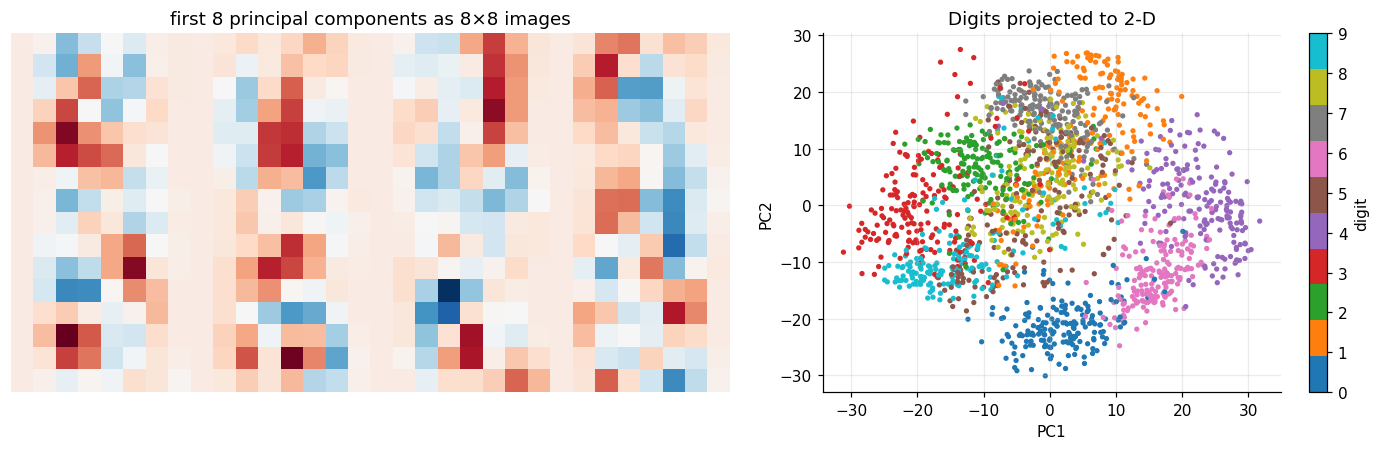

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
tile = np.vstack([np.hstack([pd.components[r * 4 + c].reshape(8, 8) for c in range(4)]) for r in range(2)])
axes[0].imshow(tile, cmap="RdBu_r"); axes[0].set_title("first 8 principal components as 8×8 images"); axes[0].axis("off")
sc = axes[1].scatter(Zd[:, 0], Zd[:, 1], c=digits.target, cmap="tab10", s=6)
axes[1].set(title="Digits projected to 2-D", xlabel="PC1", ylabel="PC2"); plt.colorbar(sc, ax=axes[1], label="digit")
plt.tight_layout(); plt.show()

### 4. The classic trap: PCA needs scaled features

PCA chases *variance*, so a feature measured in big units dominates. The wine dataset has `proline` in the hundreds or thousands and most other features around 1: unscaled, PC1 is basically just proline. Standardise first (mean 0, std 1) and the variance spreads over many features.

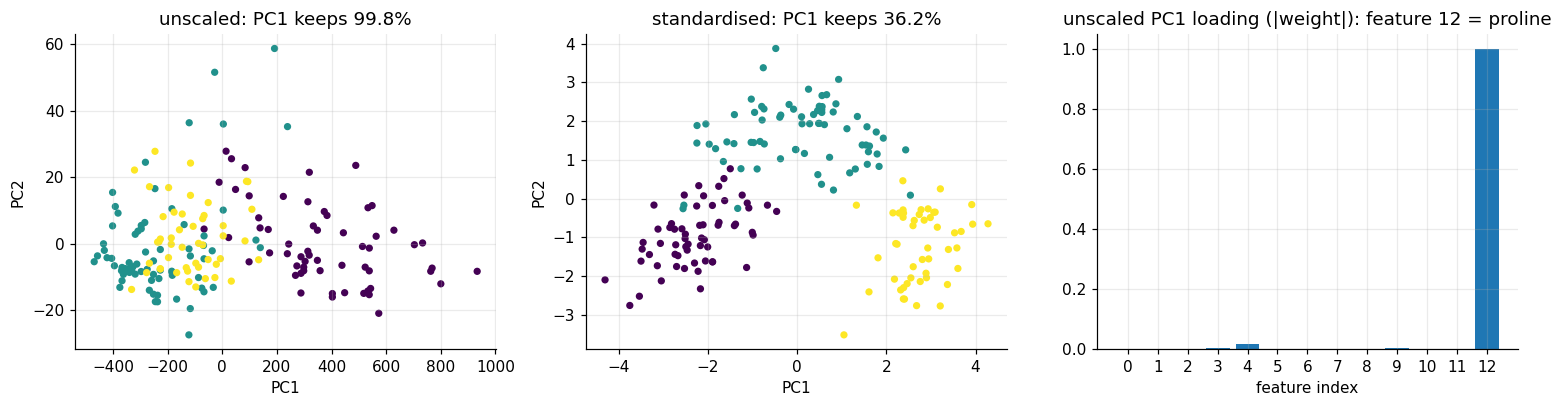

In [7]:
from sklearn.datasets import load_wine

wine = load_wine()
raw, scaled = wine.data, (wine.data - wine.data.mean(0)) / wine.data.std(0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, data, title in [(axes[0], raw, "unscaled"), (axes[1], scaled, "standardised")]:
    p = PCA(n_components=2).fit(data); Zw = p.transform(data)
    ax.scatter(*Zw.T, c=wine.target, cmap="viridis", s=14)
    ax.set_title(f"{title}: PC1 keeps {p.explained_variance_ratio_[0]:.1%}")
    ax.set(xlabel="PC1", ylabel="PC2")
load = PCA(n_components=1).fit(raw).components[0]
axes[2].bar(range(13), np.abs(load)); axes[2].set(xticks=range(13), xlabel="feature index", title="unscaled PC1 loading (|weight|): feature 12 = proline")
plt.tight_layout(); plt.show()

## Check against scikit-learn

Explained variance must match exactly. Components can differ by sign (an eigenvector and its negative are equally valid), so projections are compared by magnitude.

In [8]:
from sklearn.decomposition import PCA as SklearnPCA

ours = PCA(n_components=2).fit(iris.data)
theirs = SklearnPCA(n_components=2).fit(iris.data)
print("explained variance ratio: ours=%s sklearn=%s" % (ours.explained_variance_ratio_.round(6), theirs.explained_variance_ratio_.round(6)))
assert np.allclose(ours.explained_variance_ratio_, theirs.explained_variance_ratio_, atol=1e-6)
assert np.allclose(np.abs(ours.transform(iris.data)), np.abs(theirs.transform(iris.data)), atol=1e-4)
print("projections match sklearn up to sign")

explained variance ratio: ours=[0.924619 0.053066] sklearn=[0.924619 0.053066]
projections match sklearn up to sign


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [9]:
import numpy as np


def test_reduces_dimensionality():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(100, 5))
    model = PCA(n_components=2).fit(X)
    transformed = model.transform(X)
    assert transformed.shape == (100, 2)


def test_recovers_dominant_axis():
    rng = np.random.default_rng(0)
    # variance almost entirely along the x-axis
    X = np.column_stack([rng.normal(scale=10, size=500), rng.normal(scale=0.1, size=500)])
    model = PCA(n_components=1).fit(X)
    assert model.explained_variance_ratio_[0] > 0.99
    # first component should point mostly along the x-axis (sign is arbitrary)
    assert abs(model.components[0][0]) > 0.99


def test_explained_variance_ratios_sum_to_one_when_full_rank():
    rng = np.random.default_rng(1)
    X = rng.normal(size=(50, 4))
    model = PCA(n_components=4).fit(X)
    assert abs(model.explained_variance_ratio_.sum() - 1.0) < 1e-9

In [10]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_reduces_dimensionality
PASS test_recovers_dominant_axis
PASS test_explained_variance_ratios_sum_to_one_when_full_rank

all 3 tests passed


## Takeaways

- **Use it for** visualising high-dimensional data, compressing or denoising it, decorrelating features before a model, or speeding up distance-based methods.
- **Assumptions / limits:** it is *linear* (curved structure needs `36_kernel_pca` or `38_tsne`), it is unsupervised (the directions of most variance need not be the ones that separate your classes; for that use `37_lda_projection`), and components are only interpretable as weighted mixes of features.
- **Pitfalls:** always standardise features measured on different scales (section 4); the sign of a component is arbitrary; choose `k` from the scree plot or from a target like "95% of variance".
- **Interview line:** *"Centre, covariance, eigendecomposition, keep the top-k eigenvectors; equivalently the SVD of the centred data. Explained variance is `λᵢ/Σλ`."*